# Extended functionality - fit the Chelyabinsk event

This notebook estimates the meteoroid radius, strength, and pancake factor that best match the supplied Chelyabinsk energy-deposition curve.

The measured entry velocity (19.2 km/s), density (3300 kg/m^3), and angle (18.3 degrees) are fixed. The fit searches the ranges in the project brief: radius 5-15 m, strength 0.1-10 MPa, and pancake factor 2-10. The solver's initial altitude is 100 km.

The objective is a least-squares match to the observed energy-deposition values, scaled by the largest observed value. Differential evolution searches the bounded parameter space; bounded least squares then refines that candidate. The project ODE solver still computes each trajectory. The optimizer does not replace the ODE solver.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import differential_evolution, least_squares

# Locate the repository so the notebook works when opened from the repo root
# or from its own examples directory.
repo_root = next(
    parent for parent in [Path.cwd(), *Path.cwd().parents]
    if (parent / "deepimpact").is_dir() and (parent / "resources").is_dir()
)
sys.path.insert(0, str(repo_root))
from deepimpact.solver import Planet

plt.style.use("seaborn-v0_8-whitegrid")


## 1. Load and inspect the measured curve

The CSV contains altitude in kilometres and inferred energy loss per unit altitude in kt TNT/km. The values are sorted by altitude for interpolation and plotting. The known entry conditions come from the project brief; radius, strength, and pancake factor are the fitted quantities.


Observation points: 128
Observed altitude range: 21.62 to 42.19 km
Known entry conditions: {'velocity': 19200.0, 'density': 3300.0, 'angle': 18.3, 'init_altitude': 100000.0}
Search bounds: {'radius_m': (5.0, 15.0), 'strength_mpa': (0.1, 10.0), 'pancake_factor': (2.0, 10.0)}


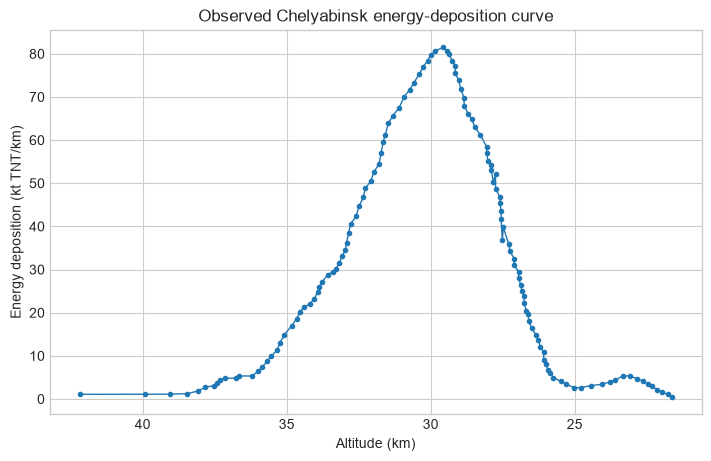

In [2]:
observations = pd.read_csv(
    repo_root / "resources" / "ChelyabinskEnergyAltitude.csv"
).sort_values("Height (km)").reset_index(drop=True)
observed_altitude_km = observations["Height (km)"].to_numpy()
observed_dedz = observations["Energy Per Unit Length (kt Km^-1)"].to_numpy()

known_entry = {
    "velocity": 19_200.0,       # m/s
    "density": 3300.0,         # kg/m^3
    "angle": 18.3,              # degrees to horizontal
    "init_altitude": 100_000.0, # m
}
parameter_bounds = {
    "radius_m": (5.0, 15.0),
    "strength_mpa": (0.1, 10.0),
    "pancake_factor": (2.0, 10.0),
}

print(f"Observation points: {len(observations)}")
print(f"Observed altitude range: {observed_altitude_km.min():.2f} to {observed_altitude_km.max():.2f} km")
print("Known entry conditions:", known_entry)
print("Search bounds:", parameter_bounds)

fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
ax.plot(observed_altitude_km, observed_dedz, "o-", markersize=3, linewidth=1)
ax.set(
    xlabel="Altitude (km)",
    ylabel="Energy deposition (kt TNT/km)",
    title="Observed Chelyabinsk energy-deposition curve",
)
ax.invert_xaxis()
plt.show()


## 2. Define how a parameter set produces a model curve

For each candidate parameter set, create a `Planet` with the requested pancake factor, solve the entry using the project's `solve_atmospheric_entry`, and calculate `dedz` from the returned dataframe. Interpolate the model deposition onto the observed altitudes so the model and measurements can be compared point by point.

A cache avoids rerunning the same candidate if the optimizer revisits it. `dt=0.05 s` is used during the fit to keep the search practical while resolving the trajectory sufficiently for this curve comparison.


In [3]:
fit_dt = 0.05
prediction_cache = {}

def predict_dedz(parameters):
    """Return model dedz at each measured altitude for [radius, strength MPa, pancake]."""
    radius_m, strength_mpa, pancake_factor = map(float, parameters)
    cache_key = tuple(np.round([radius_m, strength_mpa, pancake_factor], 8))
    if cache_key in prediction_cache:
        return prediction_cache[cache_key]

    planet = Planet(pancake_factor=pancake_factor)
    trajectory = planet.solve_atmospheric_entry(
        radius=radius_m,
        velocity=known_entry["velocity"],
        density=known_entry["density"],
        strength=strength_mpa * 1e6,
        angle=known_entry["angle"],
        init_altitude=known_entry["init_altitude"],
        dt=fit_dt,
    )
    energy = planet.calculate_energy(trajectory)
    model_altitude_km = energy["altitude"].to_numpy() / 1000.0
    model_dedz = energy["dedz"].to_numpy()
    valid = np.isfinite(model_altitude_km) & np.isfinite(model_dedz)
    order = np.argsort(model_altitude_km[valid])
    sorted_altitude = model_altitude_km[valid][order]
    sorted_dedz = model_dedz[valid][order]

    if (
        observed_altitude_km.min() < sorted_altitude.min()
        or observed_altitude_km.max() > sorted_altitude.max()
    ):
        raise ValueError("The model trajectory does not cover all observed altitudes.")

    prediction = np.interp(
        observed_altitude_km,
        sorted_altitude,
        np.maximum(sorted_dedz, 1e-8),
    )
    prediction_cache[cache_key] = prediction
    return prediction

observed_scale = np.max(observed_dedz)

def scaled_residuals(parameters):
    """Residuals in observed units, scaled by the observed curve's peak."""
    return (predict_dedz(parameters) - observed_dedz) / observed_scale


## 3. Search and refine the fit

The bounded search only explores the ranges specified above. A fixed random seed makes the global-search stage reproducible. The second stage refines the best candidate. The reported fit is the best result found by this objective and search budget; it does not prove that the inferred physical parameters are unique.


In [4]:
search = differential_evolution(
    lambda parameters: np.mean(scaled_residuals(parameters) ** 2),
    bounds=[
        parameter_bounds["radius_m"],
        parameter_bounds["strength_mpa"],
        parameter_bounds["pancake_factor"],
    ],
    seed=20261117,
    popsize=6,
    maxiter=12,
    tol=0.005,
    polish=False,
    workers=1,
)

refined = least_squares(
    scaled_residuals,
    x0=search.x,
    bounds=([5.0, 0.1, 2.0], [15.0, 10.0, 10.0]),
    x_scale=[5.0, 3.0, 4.0],
    diff_step=[0.01, 0.02, 0.01],
    max_nfev=60,
)

best_parameters = refined.x
best_radius_m, best_strength_mpa, best_pancake_factor = best_parameters
best_model_dedz = predict_dedz(best_parameters)

# Use the earlier A2 example parameters as a baseline for comparison.
baseline_parameters = np.array([10.0, 1.0, 6.5])
baseline_model_dedz = predict_dedz(baseline_parameters)

def fit_metrics(model):
    residual = model - observed_dedz
    rmse = np.sqrt(np.mean(residual**2))
    normalized_rmse = rmse / observed_scale
    r_squared = 1.0 - np.sum(residual**2) / np.sum(
        (observed_dedz - np.mean(observed_dedz)) ** 2
    )
    return rmse, normalized_rmse, r_squared

baseline_metrics = fit_metrics(baseline_model_dedz)
best_metrics = fit_metrics(best_model_dedz)
fit_summary = pd.DataFrame(
    [
        {
            "case": "Baseline (10 m, 1 MPa, 6.5)",
            "radius (m)": baseline_parameters[0],
            "strength (MPa)": baseline_parameters[1],
            "pancake factor": baseline_parameters[2],
            "RMSE (kt/km)": baseline_metrics[0],
            "RMSE / observed peak": baseline_metrics[1],
            "R squared": baseline_metrics[2],
        },
        {
            "case": "Best fit found",
            "radius (m)": best_radius_m,
            "strength (MPa)": best_strength_mpa,
            "pancake factor": best_pancake_factor,
            "RMSE (kt/km)": best_metrics[0],
            "RMSE / observed peak": best_metrics[1],
            "R squared": best_metrics[2],
        },
    ]
)
print(f"Global-search evaluations: {search.nfev}")
print(f"Local-refinement evaluations: {refined.nfev}")
print(f"Fit time step: {fit_dt} s")
fit_summary


Global-search evaluations: 234
Local-refinement evaluations: 18
Fit time step: 0.05 s


,case,radius (m),strength (MPa),pancake factor,RMSE (kt/km),RMSE / observed peak,R squared
0,"Baseline (10 m, 1 MPa, 6.5)",10.00000,1.000000,6.500000,32.161234,0.394592,-0.525366
1,Best fit found,9.02744,4.647683,6.284707,7.302775,0.089599,0.921353


## 4. Compare observed and fitted curves

The left panel overlays measurements, the best-fit model, and the baseline model. The right panel shows the best-fit residual (model minus observation) in kt/km. This makes it easier to see both the overall match and where the model remains high or low.


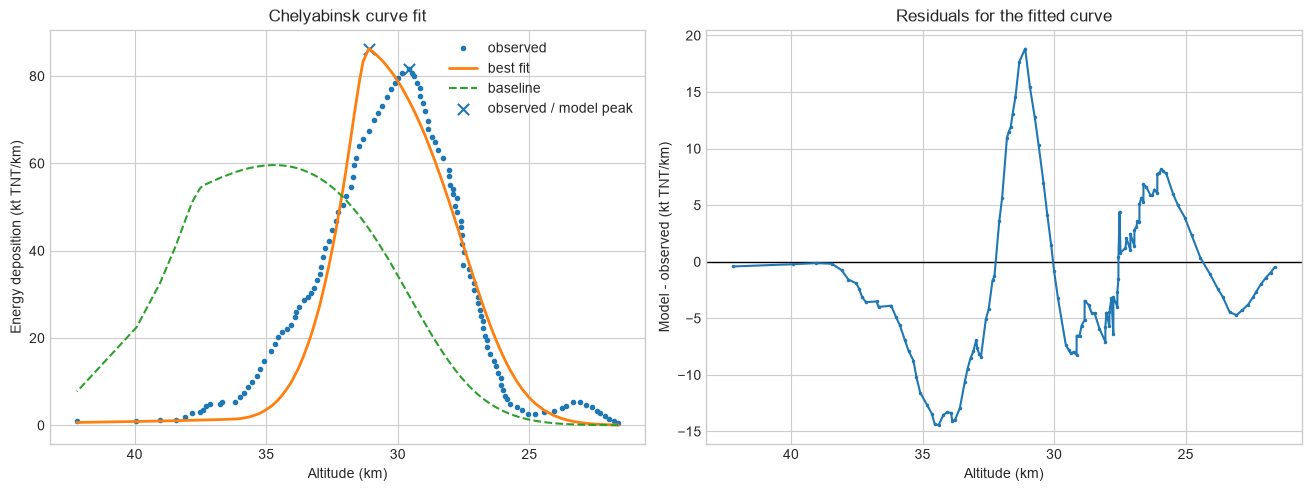

Observed peak: 81.50 kt/km at 29.56 km
Model peak: 86.28 kt/km at 31.10 km
Best-fit parameters within bounds: radius=9.027 m, strength=4.648 MPa, pancake_factor=6.285


In [5]:
fit_residual = best_model_dedz - observed_dedz
observed_peak_index = int(np.argmax(observed_dedz))
model_peak_index = int(np.argmax(best_model_dedz))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
axes[0].plot(
    observed_altitude_km,
    observed_dedz,
    "o",
    markersize=3,
    label="observed",
)
axes[0].plot(
    observed_altitude_km,
    best_model_dedz,
    linewidth=2,
    label="best fit",
)
axes[0].plot(
    observed_altitude_km,
    baseline_model_dedz,
    linestyle="--",
    linewidth=1.5,
    label="baseline",
)
axes[0].scatter(
    [observed_altitude_km[observed_peak_index], observed_altitude_km[model_peak_index]],
    [observed_dedz[observed_peak_index], best_model_dedz[model_peak_index]],
    marker="x",
    s=65,
    label="observed / model peak",
)
axes[0].set(
    xlabel="Altitude (km)",
    ylabel="Energy deposition (kt TNT/km)",
    title="Chelyabinsk curve fit",
)
axes[0].invert_xaxis()
axes[0].legend()

axes[1].axhline(0.0, color="black", linewidth=1)
axes[1].plot(observed_altitude_km, fit_residual, ".-", markersize=3)
axes[1].set(
    xlabel="Altitude (km)",
    ylabel="Model - observed (kt TNT/km)",
    title="Residuals for the fitted curve",
)
axes[1].invert_xaxis()
plt.show()

print(
    "Observed peak: "
    f"{observed_dedz[observed_peak_index]:.2f} kt/km at "
    f"{observed_altitude_km[observed_peak_index]:.2f} km"
)
print(
    "Model peak: "
    f"{best_model_dedz[model_peak_index]:.2f} kt/km at "
    f"{observed_altitude_km[model_peak_index]:.2f} km"
)
print(
    "Best-fit parameters within bounds: "
    f"radius={best_radius_m:.3f} m, "
    f"strength={best_strength_mpa:.3f} MPa, "
    f"pancake_factor={best_pancake_factor:.3f}"
)
